In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.float_format", "{:,.2f}".format)

sales = pd.read_csv("../data/processed/sales_clean.csv", parse_dates=["invoicedate"])
sales = sales.dropna(subset=["customer_id"]).copy()
sales["customer_id"] = sales["customer_id"].astype(int)

snapshot = sales["invoicedate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot.date(), "| Customers:", sales["customer_id"].nunique())


Snapshot date: 2011-12-10 | Customers: 5878


C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_16024\2890248775.py:9: DtypeWarning: Columns (0: invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv("../data/processed/sales_clean.csv", parse_dates=["invoicedate"])


In [2]:
rfm = sales.groupby("customer_id").agg(
    recency=("invoicedate", lambda s: (snapshot - s.max()).days),
    frequency=("invoice", "nunique"),
    monetary=("revenue", "sum"),
).reset_index()

rfm = rfm[rfm["monetary"] > 0]
rfm.describe()


,customer_id,recency,frequency,monetary
count,"5,878.00","5,878.00","5,878.00","5,878.00"
mean,"15,315.31",201.33,6.29,"2,955.90"
std,"1,715.57",209.34,13.01,"14,440.85"
min,"12,346.00",1.00,1.00,2.95
25%,"13,833.25",26.00,1.00,342.28
50%,"15,314.50",96.00,3.00,867.74
75%,"16,797.75",380.00,7.00,"2,248.30"
max,"18,287.00",739.00,398.00,"580,987.04"


In [3]:
rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first"),   5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"),  5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["rfm_total"] = rfm["r_score"] + rfm["f_score"] + rfm["m_score"]
rfm.head()


,customer_id,recency,frequency,monetary,r_score,f_score,m_score,rfm_total
0,12346,326,12,"77,556.46",2,5,5,12
1,12347,2,8,"4,921.53",5,4,5,14
2,12348,75,5,"2,019.40",3,4,4,11
3,12349,19,4,"4,428.69",5,3,5,13
4,12350,310,1,334.40,2,1,2,5


In [4]:
conditions = [
    (rfm["r_score"] >= 4) & (rfm["f_score"] >= 4),
    (rfm["r_score"] >= 3) & (rfm["f_score"] >= 3),
    (rfm["r_score"] >= 4) & (rfm["f_score"] <= 2),
    (rfm["r_score"] <= 2) & (rfm["f_score"] >= 3),
    (rfm["r_score"] <= 2) & (rfm["f_score"] <= 2),
]
names = ["Champions", "Loyal Customers", "New / Promising", "At Risk", "Lost"]
rfm["segment"] = np.select(conditions, names, default="Need Attention")

seg = rfm.groupby("segment").agg(
    customers=("customer_id", "count"),
    revenue=("monetary", "sum"),
    avg_recency_days=("recency", "mean"),
    avg_orders=("frequency", "mean"),
    avg_spend=("monetary", "mean"),
).reset_index()
seg["pct_customers"] = seg["customers"] / seg["customers"].sum() * 100
seg["pct_revenue"]   = seg["revenue"] / seg["revenue"].sum() * 100
seg = seg.sort_values("revenue", ascending=False)
seg


,segment,customers,revenue,avg_recency_days,avg_orders,avg_spend,pct_customers,pct_revenue
1,Champions,1473,"11,983,421.69",20.13,15.69,"8,135.38",25.06,68.97
3,Loyal Customers,1229,"2,549,954.54",78.34,5.45,"2,074.82",20.91,14.68
0,At Risk,825,"1,590,384.58",368.88,4.94,"1,927.74",14.04,9.15
2,Lost,1526,"655,444.68",458.75,1.25,429.52,25.96,3.77
5,New / Promising,441,"391,838.26",27.97,1.46,888.52,7.50,2.26
4,Need Attention,384,"203,760.52",106.22,1.36,530.63,6.53,1.17


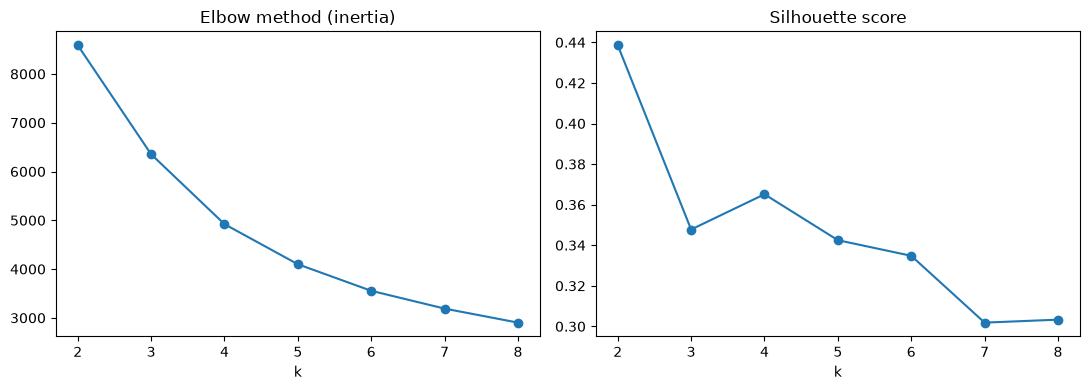

In [5]:
X  = np.log1p(rfm[["recency", "frequency", "monetary"]])
Xs = StandardScaler().fit_transform(X)

ks, inertia, sil = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertia, marker="o"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, marker="o");     ax[1].set_title("Silhouette score");        ax[1].set_xlabel("k")
plt.tight_layout()
os.makedirs("../outputs/charts", exist_ok=True)
plt.savefig("../outputs/charts/05_kmeans_k_selection.png", dpi=150); plt.show()


In [6]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
rfm["cluster"] = km.labels_

profile = rfm.groupby("cluster").agg(
    customers=("customer_id", "count"),
    avg_recency_days=("recency", "mean"),
    avg_orders=("frequency", "mean"),
    avg_spend=("monetary", "mean"),
    total_revenue=("monetary", "sum"),
).reset_index()
profile["pct_customers"] = profile["customers"] / profile["customers"].sum() * 100
profile["pct_revenue"]   = profile["total_revenue"] / profile["total_revenue"].sum() * 100
profile


,cluster,customers,avg_recency_days,avg_orders,avg_spend,total_revenue,pct_customers,pct_revenue
0,0,1974,395.15,1.38,317.76,"627,259.20",33.58,3.61
1,1,1250,28.31,3.05,855.51,"1,069,386.18",21.27,6.15
2,2,1462,229.26,5.08,"1,954.20","2,857,044.59",24.87,16.44
3,3,1192,27.55,19.31,"10,755.97","12,821,114.30",20.28,73.79


In [7]:
cluster_names = {
    0: "Dormant / Churned",
    1: "Regular / Growing",
    2: "At-Risk / Slipping",
    3: "High-Value Active"
}
rfm["cluster_name"] = rfm["cluster"].map(cluster_names)
rfm["cluster_name"].value_counts()


cluster_name
Dormant / Churned     1974
At-Risk / Slipping    1462
Regular / Growing     1250
High-Value Active     1192
Name: count, dtype: int64

In [8]:
pd.crosstab(rfm["segment"], rfm["cluster_name"])


cluster_name,At-Risk / Slipping,Dormant / Churned,High-Value Active,Regular / Growing
segment,,,,
At Risk,625,186,14,0
Champions,109,1,1062,301
Lost,92,1434,0,0
Loyal Customers,597,49,115,468
Need Attention,39,266,0,79
New / Promising,0,38,1,402


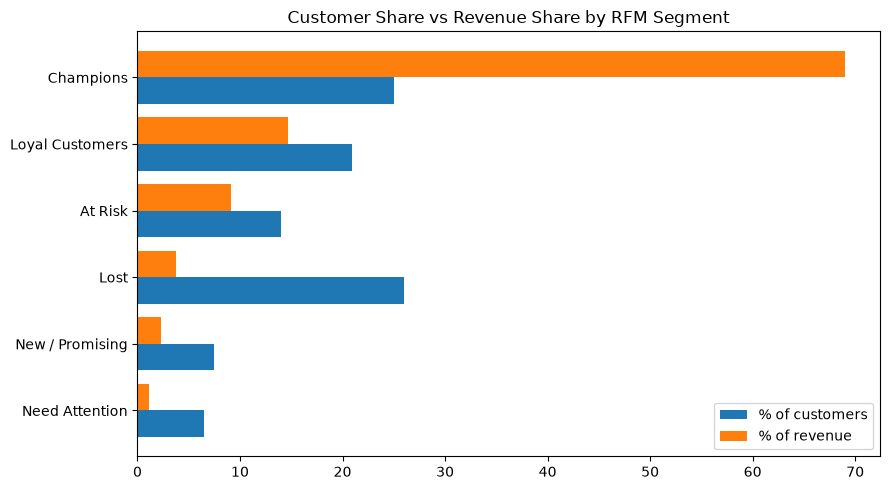

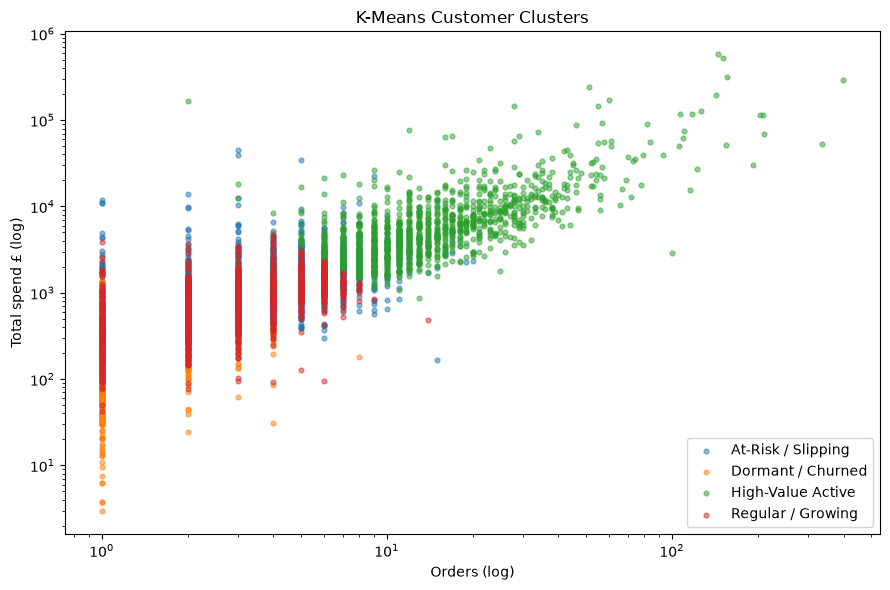

In [9]:
# 1. Customers vs revenue share by RFM segment
s = seg.sort_values("pct_revenue")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(s))
ax.barh(y - 0.2, s["pct_customers"], height=0.4, label="% of customers")
ax.barh(y + 0.2, s["pct_revenue"],   height=0.4, label="% of revenue")
ax.set_yticks(y); ax.set_yticklabels(s["segment"]); ax.legend()
ax.set_title("Customer Share vs Revenue Share by RFM Segment")
plt.tight_layout(); plt.savefig("../outputs/charts/06_rfm_segments.png", dpi=150); plt.show()

# 2. K-Means clusters: frequency vs monetary (log scales)
fig, ax = plt.subplots(figsize=(9, 6))
for name, g in rfm.groupby("cluster_name"):
    ax.scatter(g["frequency"], g["monetary"], s=12, alpha=.5, label=name)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Orders (log)"); ax.set_ylabel("Total spend £ (log)")
ax.set_title("K-Means Customer Clusters"); ax.legend()
plt.tight_layout(); plt.savefig("../outputs/charts/07_kmeans_clusters.png", dpi=150); plt.show()


In [10]:
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../outputs/reports", exist_ok=True)

rfm.to_csv("../data/processed/customer_rfm_segments.csv", index=False)
seg.to_csv("../outputs/reports/rfm_rule_summary.csv", index=False)
profile.to_csv("../outputs/reports/kmeans_cluster_summary.csv", index=False)
print("Saved customer_rfm_segments.csv and summary reports!")


Saved customer_rfm_segments.csv and summary reports!


In [11]:
os.makedirs("../outputs/reports", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

rfm.to_csv("../outputs/reports/rfm_customers.csv", index=False)
rfm.to_csv("../data/processed/rfm_customers.csv", index=False)
seg.to_csv("../outputs/reports/rfm_segment_summary.csv", index=False)
profile.to_csv("../outputs/reports/kmeans_cluster_profile.csv", index=False)
print("Saved.", len(rfm), "customers scored")


Saved. 5878 customers scored
